# 05 - Trực quan hóa dữ liệu giá nhà Amsterdam với Matplotlib và Seaborn

Mục tiêu: bài mẫu 1.2.2, tạo biểu đồ cột Top 10 khu vực giá cao nhất theo 3 mức (basic, advanced 1, advanced 2).

## 1. Load data và chuẩn bị

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
FIG_DIR = ROOT / 'figures'
REPORT_DIR = ROOT / 'reports'
FIG_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


def doc_csv(path, **kwargs):
    return pd.read_csv(path, sep=None, engine='python', **kwargs)


def can_file(*names):
    for name in names:
        if (DATA_DIR / name).exists():
            return DATA_DIR / name
    raise FileNotFoundError(f'Không thấy {names} trong {DATA_DIR}. Xem data/README.txt để biết cách tải.')


def mo_ta_thong_ke(frame):
    rows = {}
    for col in frame.select_dtypes(include=np.number).columns:
        s = frame[col].dropna()
        if s.empty:
            continue
        q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
        iqr = q3 - q1
        rows[col] = {
            'count': s.size, 'mean': s.mean(), 'median': s.median(), 'mode': s.mode().iloc[0],
            'variance': s.var(), 'std': s.std(), 'min': s.min(), 'max': s.max(), 'range': s.max() - s.min(),
            'P60': np.percentile(s, 60), 'Q1': q1, 'Q2': q2, 'Q3': q3, 'IQR': iqr,
            'skew': s.skew(), 'kurtosis': s.kurt(),
            'so_outlier_iqr': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        }
    return pd.DataFrame(rows).T


def kiem_tra_chat_luong(frame, ten):
    print(f'=== {ten} ===')
    print('Shape:', frame.shape)
    print('Số dòng trùng lặp:', int(frame.duplicated().sum()))
    thieu = frame.isna().sum()
    print('Giá trị thiếu theo cột:')
    print(thieu[thieu > 0] if thieu.sum() else '  Không có giá trị thiếu')


def luoi(cols, ve, ncols=4, size=(4.5, 3.2)):
    cols = list(cols)
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, cols):
        ve(ax, col)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    return fig


def luu_hinh(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def cap_nhat_summary(notebook, dataset, frame):
    tk = mo_ta_thong_ke(frame)
    row = {
        'notebook': notebook, 'dataset': dataset, 'rows': len(frame), 'cols': frame.shape[1],
        'numeric_cols': len(frame.select_dtypes(include=np.number).columns),
        'categorical_cols': len(frame.select_dtypes(exclude=np.number).columns),
        'missing_cells': int(frame.isna().sum().sum()), 'duplicate_rows': int(frame.duplicated().sum()),
        'outlier_cells_iqr': int(tk['so_outlier_iqr'].sum()) if len(tk) else 0,
    }
    path = FIG_DIR / 'results_summary.csv'
    old = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=list(row))
    old = old[old['notebook'] != notebook]
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print('Đã cập nhật:', path.name)

houses = pd.read_csv(can_file('HousingPricesData.csv'), usecols=lambda c: c in ['Zip', 'Price', 'Area', 'Room'])
kiem_tra_chat_luong(houses, 'Amsterdam house prices')
houses['Price'] = pd.to_numeric(houses['Price'], errors='coerce')
houses = houses.dropna(subset=['Price', 'Area']).copy()
houses['PriceperSqm'] = houses['Price'] / houses['Area']
houses['Price_trieu'] = houses['Price'] / 1e6  

top10 = houses.sort_values('Price', ascending=False).head(10).copy()
top10['label'] = top10['Zip'].astype(str) + top10.groupby('Zip').cumcount().map(lambda i: '' if i == 0 else f'-{i + 1}')
display(top10[['label', 'Price', 'Area', 'Room', 'PriceperSqm']])

=== Amsterdam house prices ===
Shape: (924, 4)
Số dòng trùng lặp: 6
Giá trị thiếu theo cột:
Price    4
dtype: int64


,label,Price,Area,Room,PriceperSqm
195,1017 EL,5950000.0,394,10,15101.522843
837,1075 AH,5850000.0,480,14,12187.500000
305,1016 AE,4900000.0,623,13,7865.168539
103,1017 ZP,4550000.0,497,13,9154.929577
179,1012 JS,4495000.0,178,5,25252.808989
33,1054 GJ,3925000.0,319,7,12304.075235
301,1031 KV,3680000.0,374,4,9839.572193
334,1015 AG,3500000.0,348,8,10057.471264
276,1075 BM,3500000.0,374,7,9358.288770
264,1076 XP,2750000.0,309,8,8899.676375


## 2. Matplotlib

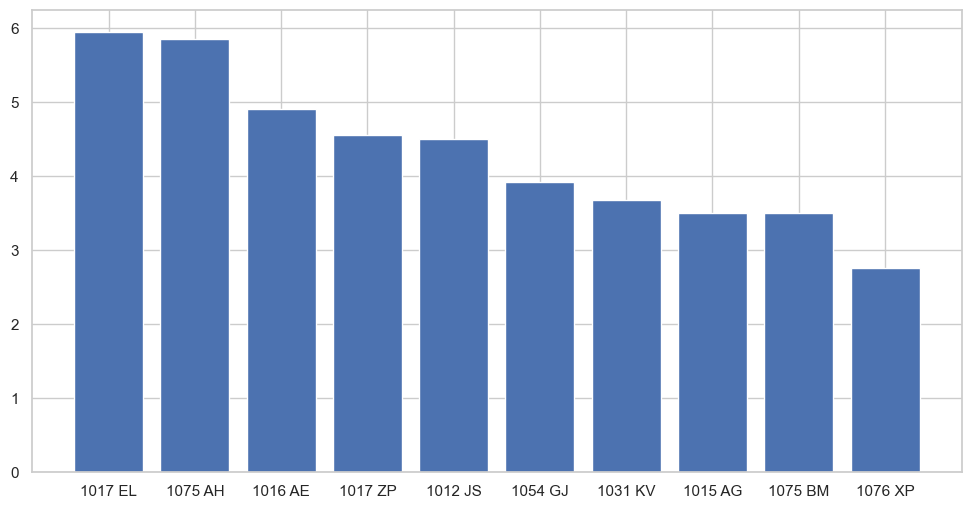

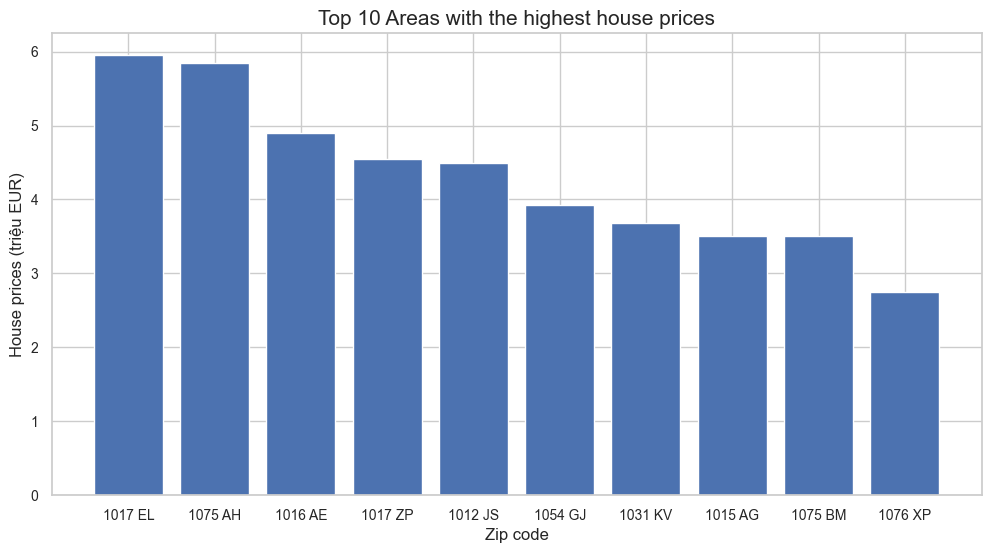

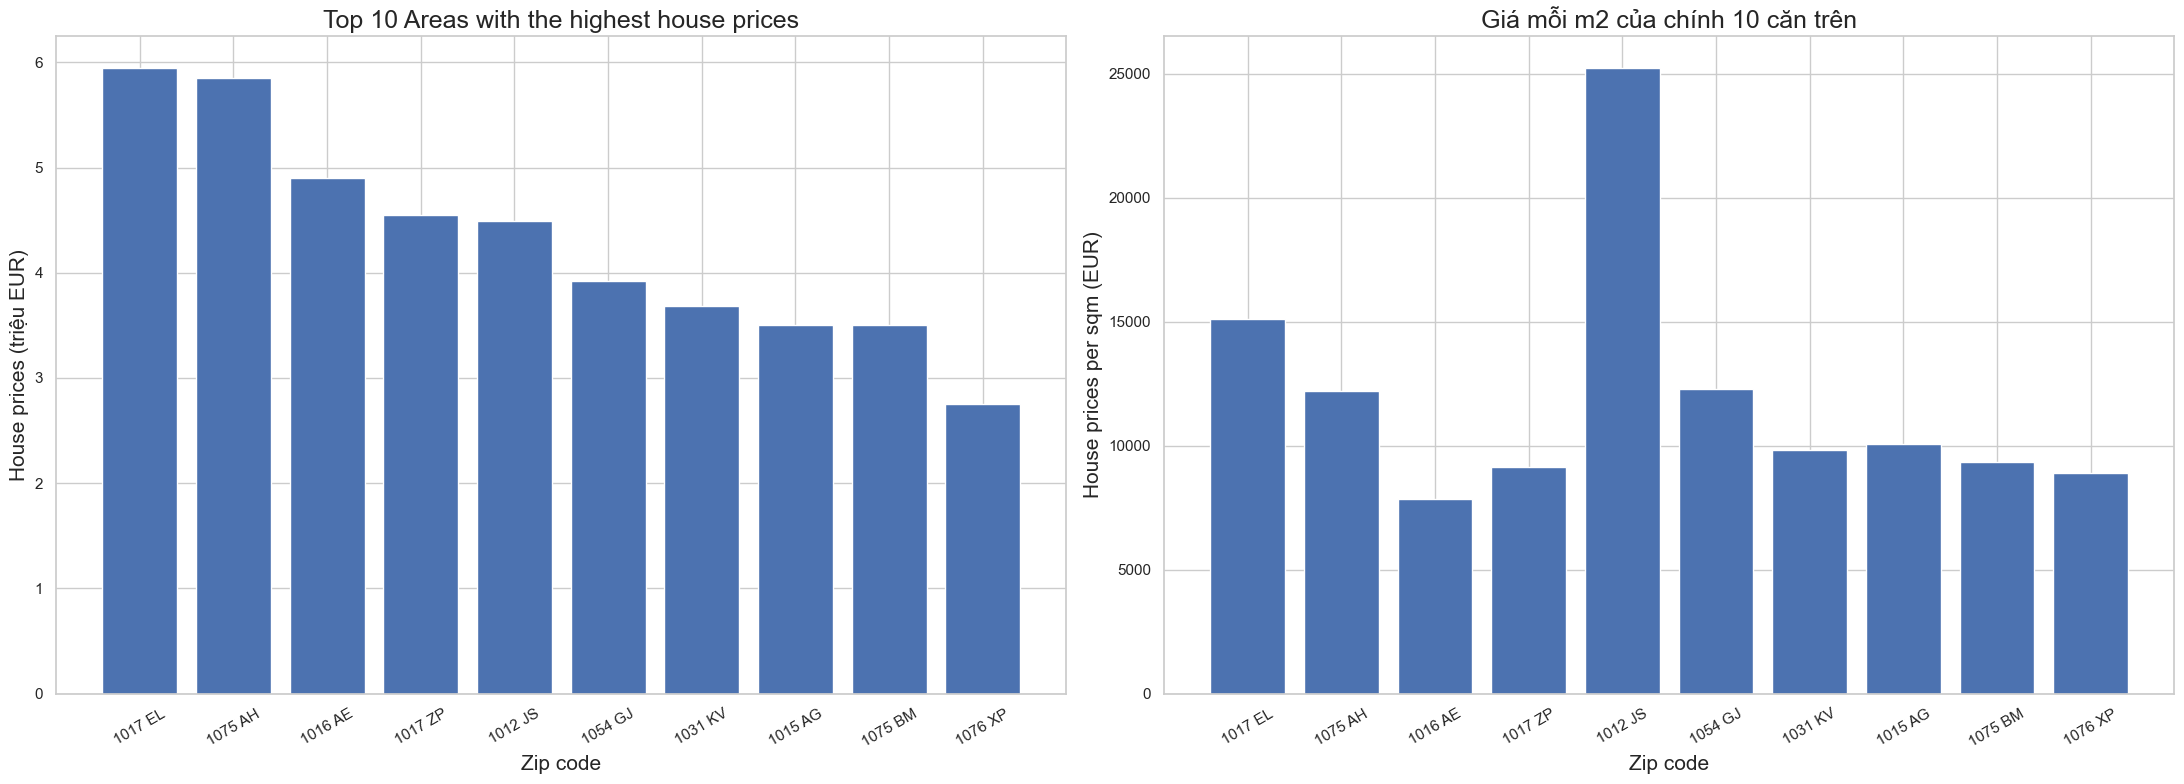

In [5]:
plt.figure(figsize=(12, 6))
plt.bar(top10['label'], top10['Price_trieu'])
plt.show()

plt.figure(figsize=(12, 6))
plt.bar(top10['label'], top10['Price_trieu'])
plt.title('Top 10 Areas with the highest house prices', fontsize=15)
plt.xlabel('Zip code', fontsize=12); plt.xticks(fontsize=10)
plt.ylabel('House prices (triệu EUR)', fontsize=12); plt.yticks(fontsize=10)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(22, 8))
axes[0].bar(top10['label'], top10['Price_trieu'])
axes[0].set_title('Top 10 Areas with the highest house prices', fontsize=18)
axes[0].set_ylabel('House prices (triệu EUR)', fontsize=15)
axes[1].bar(top10['label'], top10['PriceperSqm'])
axes[1].set_title('Giá mỗi m2 của chính 10 căn trên', fontsize=18)
axes[1].set_ylabel('House prices per sqm (EUR)', fontsize=15)
for ax in axes:
    ax.set_xlabel('Zip code', fontsize=15); ax.tick_params(axis='x', labelsize=11, rotation=30)
luu_hinh('05_matplotlib_top10')

## 3. Seaborn

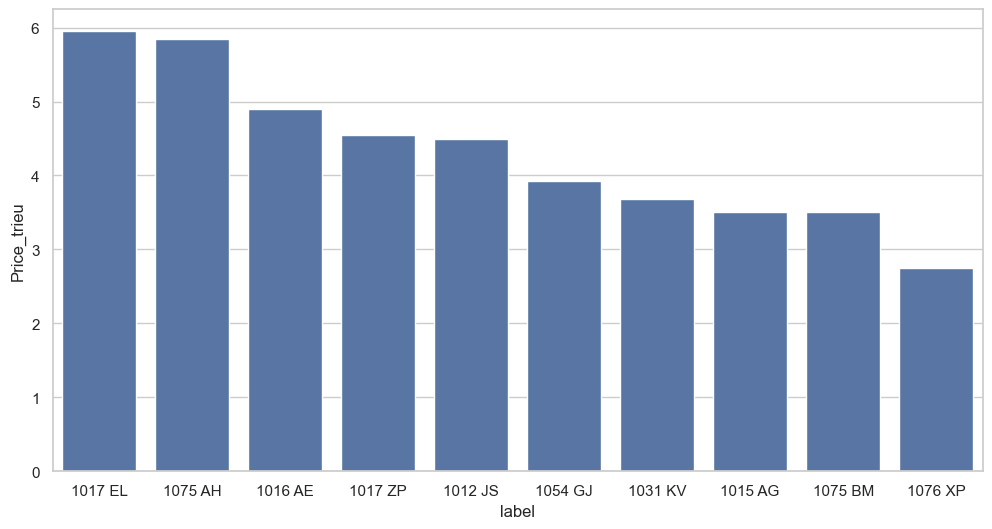

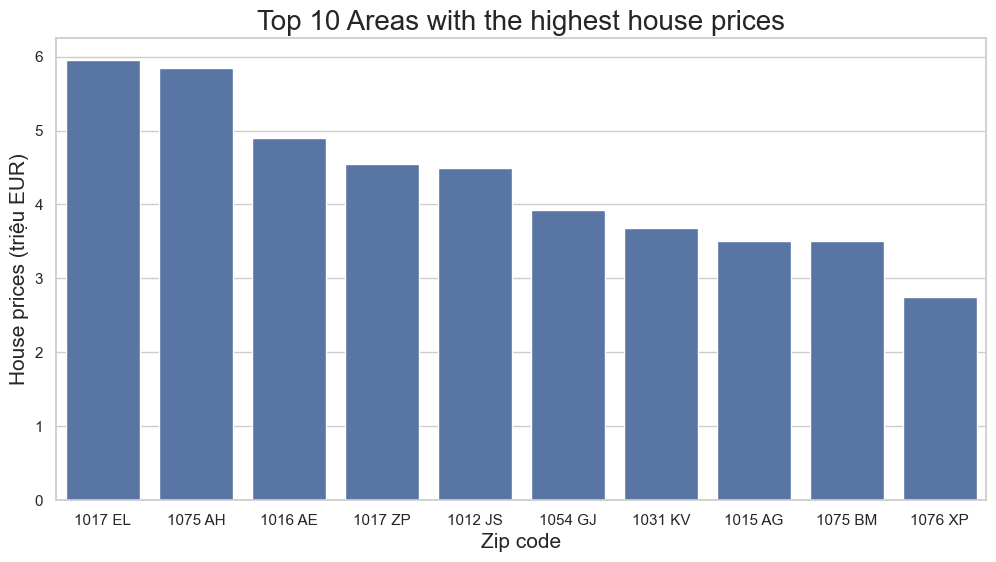

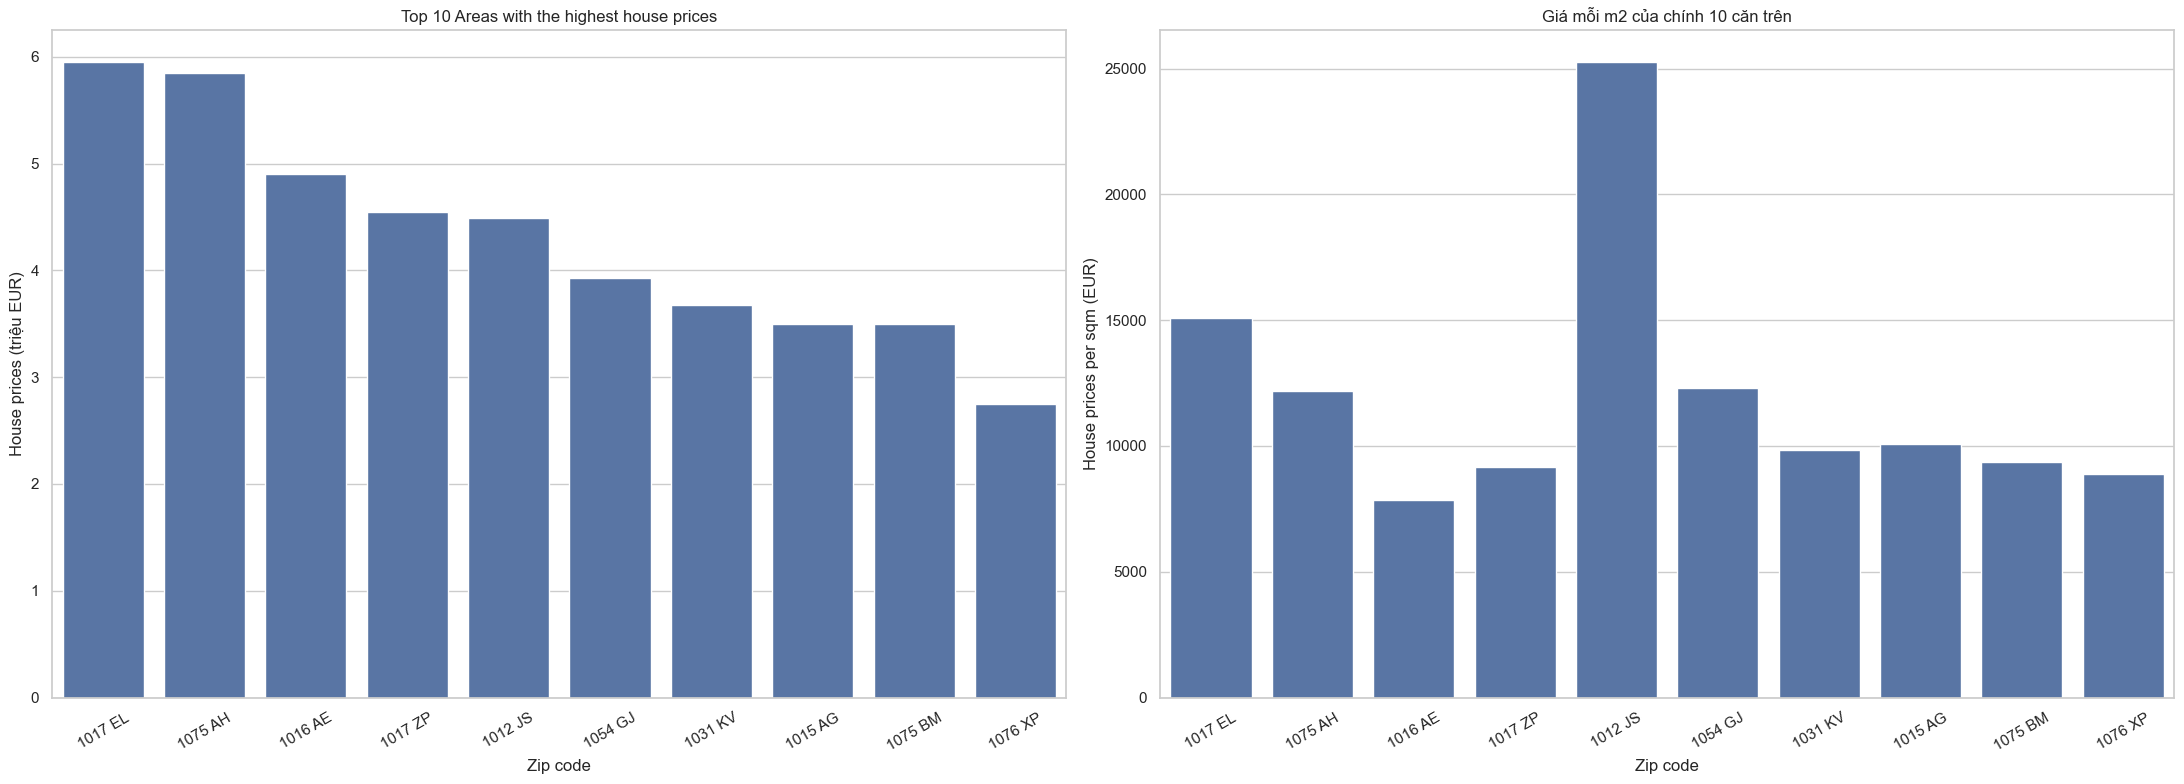

Đã cập nhật: results_summary.csv


In [6]:
plt.figure(figsize=(12, 6))
sns.barplot(data=top10, x='label', y='Price_trieu', errorbar=None)
plt.show()

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=top10, x='label', y='Price_trieu', errorbar=None)
ax.set_xlabel('Zip code', fontsize=15)
ax.set_ylabel('House prices (triệu EUR)', fontsize=15)
ax.set_title('Top 10 Areas with the highest house prices', fontsize=20)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(22, 8))
sns.barplot(data=top10, x='label', y='Price_trieu', ax=axes[0], errorbar=None)
axes[0].set_title('Top 10 Areas with the highest house prices')
axes[0].set_xlabel('Zip code'); axes[0].set_ylabel('House prices (triệu EUR)')
sns.barplot(data=top10, x='label', y='PriceperSqm', ax=axes[1], errorbar=None)
axes[1].set_title('Giá mỗi m2 của chính 10 căn trên')
axes[1].set_xlabel('Zip code'); axes[1].set_ylabel('House prices per sqm (EUR)')
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
luu_hinh('05_seaborn_top10')

cap_nhat_summary('05_houseprices_viz', 'HousingPricesData.csv', houses[['Price', 'Area', 'Room', 'PriceperSqm']])

## 4. Nhận xét

Matplotlib cần tự cấu hình từng thành phần (`title`, `xlabel`, ...), Seaborn cho bảng màu và kiểu mặc định đẹp hơn với ít dòng lệnh hơn, nhưng cả hai tạo ra cùng một loại biểu đồ. Căn nhà đắt nhất chưa chắc có giá mỗi m2 cao nhất; vì vậy hai biểu đồ đặt cạnh nhau cho thấy nhận định khác nhau, và nên dùng `PriceperSqm` khi so sánh các khu vực. Ghi chú: Zip lặp lại trong top 10 được gắn hậu tố (`-2`) để các cột không chồng lên nhau.